In [1]:
# Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import random
import math
import ipynbname
import os
import networkx as nx

<div><h2 style = 'text-align:center'>Numerical Integration Methods for Ordinary Differential Equations (ODEs)</h2>


Systems of ODE are often challenging to solve analytically; therefore, numerical integration methods are commonly used to numerically calculate their trajectories from ODE. In particular, for a continuous system (or flow), the general form of an ordinary differential equation
$$
 \begin{equation}
    \dot{y} = f(t, y),
 \end{equation}$$
with initial condition
$$\begin{equation*}
    y(t_{0}) = y_{0},
\end{equation*}
$$
where $\dot{y}$ is the time derivative of $y$ variable and $f(t,y)$ is the function of differential equation. Let the analytical solution of the system be $F_{t}$ and its numerical approximation $Y_{t}$ at time $t$. The cumulative error between the analytical solution and its numerical approximation is called **global truncation error**,
$$\begin{equation*}
    E(t) = F_{t} - Y_{t}.
\end{equation*}$$
The error between the analytical solution of an ODE system and its approximation in one iteration is called the **local truncation error**, and depends on the numerical method chosen. However, in practise, computers carry out the computation with finite-precision at each time step, **round-off error** arises given by
$$\begin{equation*}
    R(t) = y_{t} - Y_{t},
\end{equation*}$$
where $y_{t}$ is actually computed from the given numerical method. This depends on the type of computer, rounding-off method, etc. 






</div>


<h3> 1. Euler Method</h3>

The fundamental approximation technique for a solution of a system of ODE is the **Euler Method**. To approximate further steps, it uses the first order solution of the Taylor series expansion, which is given
$$\begin{align}
    f(x+h) &= f(x) + h f'(x) + h^{2} \frac{f''(x)}{2!} + h^{3} \frac{f^{(3)}(x)}{3!} + \ldots \nonumber \\
    &= f(x) + \sum_{n=1} h^{n} \frac{f^{(n)}(x)}{n!}, \nonumber
\end{align}$$

where $f^{(n)}$ denotes the $n^{th}$ derivation of function $f$. Using the first two terms of the Taylor series expansion, we can derive the Euler method,

$$\begin{equation*}
    y_{t+1} = y_{t} + hf(t,y_{t}),
\end{equation*}$$

where $h$ is the step size. This method computes an approximation of the function over each step using the previous approximation and the differential value of the equation at that time step. The algorithm shows the pseudocode for the implementation of the Euler method.


$$\begin{array}{l} \textbf{Algorithm 1: } \text{Algorithm for Euler method} \\ \hline 1: \quad \text{Define } \mathbf{f(t,y)}\\
2: \quad \text{ Set initial value } y=y_{0} \\
3: \quad \text{ Input step size } h \text{ and number of steps } n \\
4: \quad \textbf{for } <j=1:n> \text{do: } \\
    \qquad \qquad f_{n} = f(t,y) \\
    \qquad \qquad y = y+hf_{n} \\
    \qquad \qquad t = t+h \\
5: \quad \text{ Return } t \text{ and } y.\\
\hline 
\end{array}$$

In [2]:
def Euler_method(f, y0, h, n, t0=0.0, return_trajectory=True, **args):
    """Numerically integrates an ODE system dy/dt = f(t, y) using the Forward Euler method.

    Parameters:
    -----------
    f                 : Callable f(t, y, **args) defining dy/dt
    y0                : Initial condition (scalar or 1D array)
    h                 : Step size
    n                 : Number of integration steps
    t0                : Initial time (default: 0.0)
    return_trajectory : If True, returns full history (t_arr, y_arr);
                        if False, returns only the final state (t_final, y_final)
    **args            : Extra parameters forwarded to f

    Returns:
    --------
    t_vals, y_vals
    """
    y = np.asarray(y0, dtype=float).copy()

    if not return_trajectory:
        t = t0
        for step in range(n):
            fn = f(t, y, **args)
            y = y + h * fn
            t = t0 + (step + 1) * h
        return t, y

    # Allocate full trajectory
    t_vals = np.linspace(t0, t0 + n * h, n + 1)

    if y.ndim == 0:
        # Scalar ODE
        y_vals = np.zeros(n + 1, dtype=float)
    else:
        # Vector / Multi-dimensional ODE system
        y_vals = np.zeros((n + 1, *y.shape), dtype=float)

    y_vals[0] = y

    for step in range(n):
        t_curr = t_vals[step]
        fn = f(t_curr, y_vals[step], **args)
        y_vals[step + 1] = y_vals[step] + h * fn

    return t_vals, y_vals

### Model 1: The Lotka-Volterra (Predator-Prey) Model

It is a 2D nonlinear ODE system where prey (x) and predator (y) populations oscillate over time.
The Equations
$$\begin{align*}
\frac{dt}{dx} &= \alpha x−\beta xy  \\
\frac{dt}{dy} &= \delta xy− \gamma y 
\end{align*}$$
where,
<lo>
    <li> $\alpha$: Exponential prey growth in the absence of predators.</li>
    <li>$\beta$: Predation rate (mass-action contact rate).</li>
    <li>$\delta$ : Conversion efficiency of consumed prey into predator offspring.</li>
    <li>$\gamma$: Natural predator mortality rate.</li>
</lo>




In [3]:
def lotka_volterra(t, y, alpha=1.1, beta=0.4, delta=0.1, gamma=0.4):
    """y[0] = prey (x)
    y[1] = predator (y)
    """
    x, p = y[0], y[1]
    dxdt = alpha * x - beta * x * p
    dpdt = delta * x * p - gamma * p
    return np.array([dxdt, dpdt])

def lotka_volterra_jacobian(
    t, y, alpha=1.1, beta=0.4, delta=0.1, gamma=0.4):
    """Jacobian matrix of the 2D Lotka-Volterra predator-prey model.

    y[0] = prey (x)
    y[1] = predator (p)
    """
    x, p = y[0], y[1]

    df1_dx = alpha - beta * p
    df1_dp = -beta * x
    df2_dx = delta * p
    df2_dp = delta * x - gamma

    return np.array([[df1_dx, df1_dp], [df2_dx, df2_dp]], dtype=float)
    
# 2. Integration parameters
y0 = np.array([10.0, 5.0])  # Initial populations: 10 prey, 5 predators
t0 = 0.0
h = 10**-3 # Euler requires a relatively small step size for stability
n = 10**5  # Total time = n * h = 50.0

# 3. Run the Euler method
t_vals, y_vals = Euler_method(
    lotka_volterra,
    y0=y0,
    h=h,
    n=n,
    t0=t0,
    return_trajectory=True,
    alpha=1.1,
    beta=0.4,
    delta=0.1,
    gamma=0.4,
)


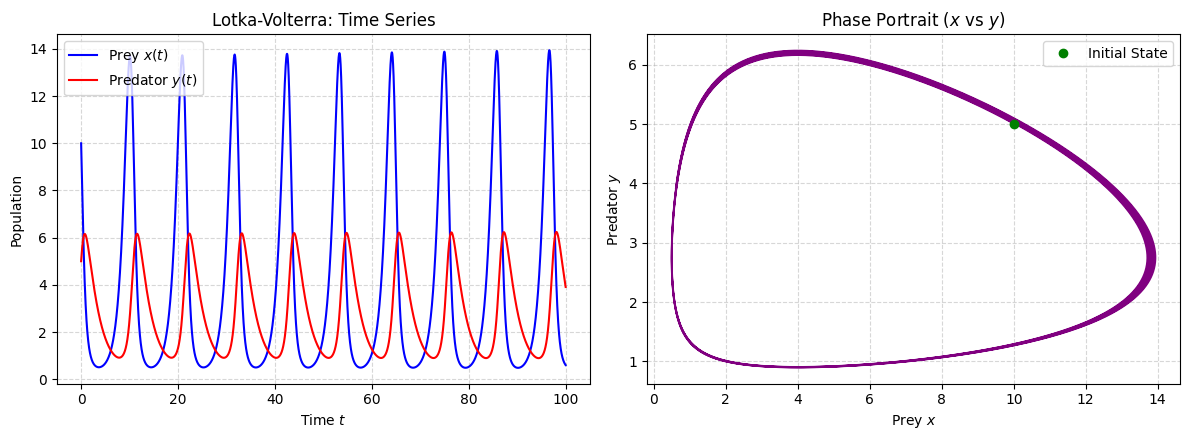

In [4]:
# 4. Plot Time Series & Phase Portrait
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Populations vs Time
ax1.plot(t_vals, y_vals[:, 0], "b-", label="Prey $x(t)$", lw=1.5)
ax1.plot(t_vals, y_vals[:, 1], "r-", label="Predator $y(t)$", lw=1.5)
ax1.set_xlabel("Time $t$")
ax1.set_ylabel("Population")
ax1.set_title("Lotka-Volterra: Time Series")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Plot 2: Phase Portrait (Prey vs Predator)
ax2.plot(y_vals[:, 0], y_vals[:, 1], "purple", lw=0.8)
ax2.plot(y0[0], y0[1], "go", label="Initial State")
ax2.set_xlabel("Prey $x$")
ax2.set_ylabel("Predator $y$")
ax2.set_title("Phase Portrait ($x$ vs $y$)")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

<h4>Euler with Lyapunov exponent calculations </h4>
Extended the Euler integrator to include tangent space variational equations and Lyapunov exponent calculation.

In [5]:
def euler_with_lyapunov(
    f,
    y0,
    t0,
    h,
    n_steps,
    df=None,
    lyap_mode="spectrum",
    n_transient=1000,
    qr_interval=10,
    **params,
):
    """Integrates dy/dt = f(t, y) via Forward Euler with flexible Lyapunov options.

    Parameters:
    -----------
    f            : Callable f(t, y, **params) returning array of shape (d,)
    y0           : Initial state vector (shape: (d,))
    t0           : Initial time
    h            : Step size
    n_steps      : Number of recording steps
    df           : Callable Jacobian df(t, y, **params) returning (d, d).
                   Required if lyap_mode is 'spectrum' or 'history'.
    lyap_mode    : Mode of Lyapunov calculation:
                   - 'none'    : Trajectory only (skips Jacobian and QR entirely).
                   - 'spectrum': Returns final sorted Lyapunov spectrum.
                   - 'history' : Returns running history of Lyapunov exponents over time.
    n_transient  : Initial burn-in steps (not included in Lyapunov sum)
    qr_interval  : Re-orthonormalize every K steps (default: 10)
    **params     : Parameters forwarded to f and df

    Returns:
    --------
    - If lyap_mode == 'none':
        t_vals, traj
    - If lyap_mode == 'spectrum':
        t_vals, traj, lyap_spectrum
    - If lyap_mode == 'history':
        t_vals, traj, lyap_t, lyap_history
    """
    valid_modes = {"none", "spectrum", "history"}
    if lyap_mode not in valid_modes:
        raise ValueError(
            f"Invalid lyap_mode '{lyap_mode}'. Expected one of {valid_modes}"
        )

    if lyap_mode in {"spectrum", "history"} and df is None:
        raise ValueError(
            f"Jacobian function `df` must be provided when lyap_mode='{lyap_mode}'."
        )

    y = np.asarray(y0, dtype=float).copy()
    d = len(y)
    t = float(t0)

    # 1. Transient burn-in
    for _ in range(n_transient):
        y = y + h * f(t, y, **params)
        t += h

    # 2. Allocate trajectory storage
    traj = np.zeros((n_steps, d), dtype=float)
    t_vals = np.zeros(n_steps, dtype=float)
    traj[0] = y
    t_vals[0] = t

    # Fast path: No Lyapunov calculation
    if lyap_mode == "none":
        for step in range(1, n_steps):
            y = y + h * f(t, y, **params)
            t += h
            traj[step] = y
            t_vals[step] = t
        return t_vals, traj

    # 3. Setup for Lyapunov evaluation
    Q = np.eye(d, dtype=float)
    lyap_sum = np.zeros(d, dtype=float)
    I = np.eye(d, dtype=float)
    M_accum = np.eye(d, dtype=float)

    # History storage if requested
    if lyap_mode == "history":
        n_qr_events = (n_steps - 1) // qr_interval
        lyap_history = np.zeros((n_qr_events, d), dtype=float)
        lyap_t = np.zeros(n_qr_events, dtype=float)
        qr_idx = 0

    # 4. Main simulation loop with variational tracking
    for step in range(1, n_steps):
        fn = f(t, y, **params)
        Jn = df(t, y, **params)

        # Euler state update
        y = y + h * fn
        t += h
        traj[step] = y
        t_vals[step] = t

        # Accumulate linear propagator (I + h * J)
        M_step = I + h * Jn
        M_accum = M_step @ M_accum

        # Orthogonalization every qr_interval steps
        if step % qr_interval == 0:
            Z = M_accum @ Q
            Q, R = np.linalg.qr(Z)

            diag_r = np.abs(np.diag(R))
            lyap_sum += np.log(diag_r)

            # Record running estimates if tracking history
            if lyap_mode == "history":
                elapsed_time = step * h
                lyap_history[qr_idx] = lyap_sum / elapsed_time
                lyap_t[qr_idx] = t
                qr_idx += 1

            M_accum = np.eye(d, dtype=float)

    # Final calculation
    completed_steps = (n_steps - 1) // qr_interval * qr_interval
    total_time = completed_steps * h
    final_spectrum = np.sort(lyap_sum / total_time)[::-1]

    if lyap_mode == "spectrum":
        return t_vals, traj, final_spectrum
    else:  # 'history'
        return t_vals, traj, lyap_t, lyap_history

In [6]:
# 2. Integration parameters
y0 = np.array([10.0, 5.0])  # Initial populations: 10 prey, 5 predators
t0 = 0.0
h = 10**-3 # Euler requires a relatively small step size for stability
n = 10**5  # Total time = n * h = 50.0
n_transient = 2000  # 10 seconds of transient burn-in

t_vals_lotka, traj_lotka, spectrum_lotka = euler_with_lyapunov(
    f=lotka_volterra,
    df=lotka_volterra_jacobian,
    y0=y0,
    t0=0.0,
    h=h,
    n_steps=n,
    n_transient=n_transient,
    qr_interval=5,
    alpha=1.1,
    beta=0.4,
    delta=0.1,
    gamma=0.4,
)

print(f"Computed Lyapunov Spectrum: λ1 = {spectrum_lotka[0]:.3f}, λ2 = {spectrum_lotka[1]:.3f}")



Computed Lyapunov Spectrum: λ1 = 0.017, λ2 = -0.031


### Model 2: Lorenz Attractors

In [7]:
# Define equations and Jacobian of Lorenz 

def lorenz(t, y, sigma=10.0, rho=28.0, beta=8.0 / 3.0):
    ''' Define equations of Lorenz '''
    x, y_coord, z = y
    dxdt = sigma * (y_coord - x)
    dydt = x * (rho - z) - y_coord
    dzdt = x * y_coord - beta * z
    return np.array([dxdt, dydt, dzdt])


def lorenz_jacobian(t, y, sigma=10.0, rho=28.0, beta=8.0 / 3.0):
    '''Define Jacobian of Lorenz '''
    x, y_coord, z = y
    return np.array(
        [[-sigma, sigma, 0.0], [rho - z, -1.0, -x], [y_coord, x, -beta]]
    )

Computed Lyapunov Spectrum: λ1 = 0.920, λ2 = 0.017, λ3 = -14.757
Actual Lyapunov Spectrum:   λ1 = 0.906, λ2 = 0.000, λ3 = -14.572


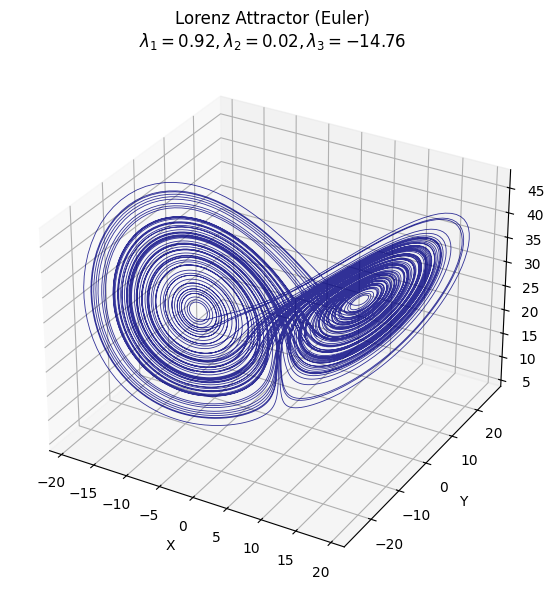

In [8]:
# Integration settings
y0 = [1.0, 1.0, 1.0]
h = 0.005  # Small step size required by explicit Euler
n_steps = 20000  # Total tracking time = 100 seconds
n_transient = 2000  # 10 seconds of transient burn-in

# 3. Run simulation
t_vals, traj, spectrum = euler_with_lyapunov(
    f=lorenz,
    df=lorenz_jacobian,
    y0=y0,
    t0=0.0,
    h=h,
    n_steps=n_steps,
    n_transient=n_transient,
    qr_interval=5,
    sigma=10.0,
    rho=28.0,
    beta=8.0/3.0
)

print(f"Computed Lyapunov Spectrum: λ1 = {spectrum[0]:.3f}, λ2 = {spectrum[1]:.3f}, λ3 = {spectrum[2]:.3f}\n"
    f"Actual Lyapunov Spectrum:   λ1 = {0.9056:.3f}, λ2 = {0.0:.3f}, λ3 = {-14.5723:.3f}")

# 4. Plot 3D Trajectory
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color="navy", lw=0.6, alpha=0.8)
ax.set_title(
    f"Lorenz Attractor (Euler)\n$\\lambda_1={spectrum[0]:.2f}, \\lambda_2={spectrum[1]:.2f}, \\lambda_3={spectrum[2]:.2f}$"
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()


<div><h3> 2. The $4^{th}-$order Runge-Kutta Method (RK4)</h3>
The RK4 method stands as the most widely recognised member of the Runge-Kutta numerical method family. This method approximates the analytical solution by expanding it to the $4^{th}$ order of its Taylor series expansion and the derivation of the coefficients. The pseudocode for the RK4 method is given in algorithm below.
    
$$\begin{array}{l} \textbf{Algorithm 2: } \text{Algorithm for the $4^{th}-$order Runge-Kutta} \\ \hline 
1: \quad \text{Define } \mathbf{f(t,y)}\\
2: \quad \text{ Set initial value } y=y_{0} \\
3: \quad \text{ Input step size } h \text{ and number of steps } n \\
4: \quad \textbf{for } <j=1:n> \text{do: } \\
    \qquad \qquad k1 = f(t,y) \\
    \qquad \qquad k2 = f(t+ \frac{h}{2}, y+\frac{h}{2}  k1) \\
    \qquad \qquad k3 = f(t+ \frac{h}{2}, y+\frac{h}{2}  k2) \\
    \qquad \qquad k4 = f(t+h, y+hk3)) \\
    \qquad \qquad y = y+(\frac{h}{6})  (k1+2 \times k2+2\times k3+k4) \\
    \qquad \qquad t = t+h \\
5: \quad \text{ Return } t \text{ and } y.\\
\hline 
\end{array}$$



</div>

In [9]:
def rk4_with_lyapunov(
    f,
    y0,
    t0,
    h,
    n_steps,
    df=None,
    lyap_mode="spectrum",
    n_transient=1000,
    qr_interval=10,
    **params,
):
    """Integrates dy/dt = f(t, y) via 4th-order Runge-Kutta (RK4) with flexible Lyapunov options.

    Parameters:
    -----------
    f            : Callable f(t, y, **params) returning 1D array of shape (d,)
    y0           : Initial state vector (shape: (d,))
    t0           : Initial time
    h            : Step size
    n_steps      : Number of recording steps
    df           : Callable Jacobian df(t, y, **params) returning 2D array (d, d).
                   Required if lyap_mode is 'spectrum' or 'history'.
    lyap_mode    : 'none'     -> Trajectory only
                   'spectrum' -> Trajectory and final sorted Lyapunov spectrum
                   'history'  -> Trajectory, time points, and running spectrum convergence
    n_transient  : Transient burn-in steps before tracking Lyapunov exponents
    qr_interval  : Number of integration steps between QR re-orthonormalizations
    **params     : Additional keyword arguments forwarded to f and df

    Returns:
    --------
    - If lyap_mode == 'none':
        t_vals, traj
    - If lyap_mode == 'spectrum':
        t_vals, traj, lyap_spectrum
    - If lyap_mode == 'history':
        t_vals, traj, lyap_t, lyap_history
    """
    valid_modes = {"none", "spectrum", "history"}
    if lyap_mode not in valid_modes:
        raise ValueError(
            f"Invalid lyap_mode '{lyap_mode}'. Expected one of {valid_modes}"
        )

    if lyap_mode in {"spectrum", "history"} and df is None:
        raise ValueError(
            f"Jacobian function `df` must be provided when lyap_mode='{lyap_mode}'."
        )

    y = np.asarray(y0, dtype=float).copy()
    d = len(y)
    t = float(t0)

    # 1. Transient burn-in via standard RK4
    for _ in range(n_transient):
        k1 = f(t, y, **params)
        k2 = f(t + 0.5 * h, y + 0.5 * h * k1, **params)
        k3 = f(t + 0.5 * h, y + 0.5 * h * k2, **params)
        k4 = f(t + h, y + h * k3, **params)
        y = y + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        t += h

    # 2. Allocate trajectory storage
    traj = np.zeros((n_steps, d), dtype=float)
    t_vals = np.zeros(n_steps, dtype=float)
    traj[0] = y
    t_vals[0] = t

    # Fast path: Trajectory only
    if lyap_mode == "none":
        for step in range(1, n_steps):
            k1 = f(t, y, **params)
            k2 = f(t + 0.5 * h, y + 0.5 * h * k1, **params)
            k3 = f(t + 0.5 * h, y + 0.5 * h * k2, **params)
            k4 = f(t + h, y + h * k3, **params)
            y = y + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
            t += h

            traj[step] = y
            t_vals[step] = t
        return t_vals, traj

    # 3. Setup for Variational / Tangent Space Tracking
    Q = np.eye(d, dtype=float)
    lyap_sum = np.zeros(d, dtype=float)

    # Accumulator for step propagators between QR re-orthonormalizations
    Phi = np.eye(d, dtype=float)

    if lyap_mode == "history":
        n_qr_events = (n_steps - 1) // qr_interval
        lyap_history = np.zeros((n_qr_events, d), dtype=float)
        lyap_t = np.zeros(n_qr_events, dtype=float)
        qr_idx = 0

    # 4. Main RK4 Loop integrating state and variational equations
    for step in range(1, n_steps):
        # Stage 1
        k1 = f(t, y, **params)
        J1 = df(t, y, **params)
        K1_phi = J1 @ Phi

        # Stage 2
        y_stage2 = y + 0.5 * h * k1
        t_stage2 = t + 0.5 * h
        k2 = f(t_stage2, y_stage2, **params)
        J2 = df(t_stage2, y_stage2, **params)
        K2_phi = J2 @ (Phi + 0.5 * h * K1_phi)

        # Stage 3
        y_stage3 = y + 0.5 * h * k2
        t_stage3 = t + 0.5 * h
        k3 = f(t_stage3, y_stage3, **params)
        J3 = df(t_stage3, y_stage3, **params)
        K3_phi = J3 @ (Phi + 0.5 * h * K2_phi)

        # Stage 4
        y_stage4 = y + h * k3
        t_stage4 = t + h
        k4 = f(t_stage4, y_stage4, **params)
        J4 = df(t_stage4, y_stage4, **params)
        K4_phi = J4 @ (Phi + h * K3_phi)

        # State update
        y = y + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        t += h
        traj[step] = y
        t_vals[step] = t

        # Propagator update
        Phi = Phi + (h / 6.0) * (K1_phi + 2 * K2_phi + 2 * K3_phi + K4_phi)

        # QR re-orthonormalization
        if step % qr_interval == 0:
            Z = Phi @ Q
            Q, R = np.linalg.qr(Z)

            diag_r = np.abs(np.diag(R))
            lyap_sum += np.log(diag_r)

            if lyap_mode == "history":
                elapsed_time = step * h
                lyap_history[qr_idx] = lyap_sum / elapsed_time
                lyap_t[qr_idx] = t
                qr_idx += 1

            # Reset propagator
            Phi = np.eye(d, dtype=float)

    # Compute final exponents
    completed_steps = ((n_steps - 1) // qr_interval) * qr_interval
    total_time = completed_steps * h
    final_spectrum = np.sort(lyap_sum / total_time)[::-1]

    if lyap_mode == "spectrum":
        return t_vals, traj, final_spectrum
    else:  # 'history'
        return t_vals, traj, lyap_t, lyap_history

Computed Lyapunov Spectrum: λ1 = 0.898, λ2 = -0.004, λ3 = -14.561
Actual Lyapunov Spectrum:   λ1 = 0.906, λ2 = 0.000, λ3 = -14.572


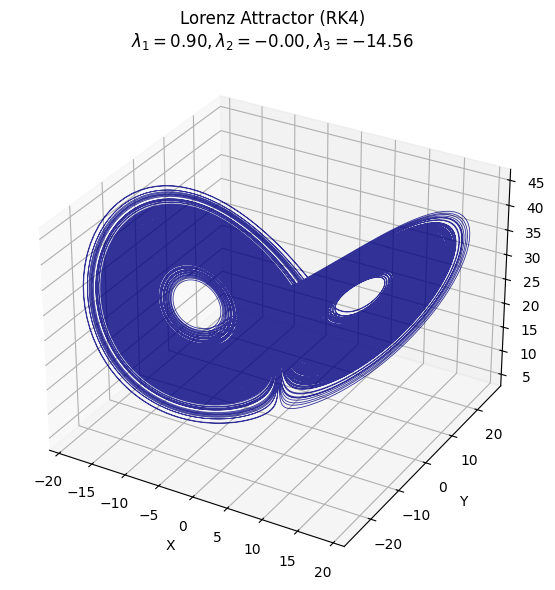

In [10]:
# 1. Integration settings
y0 = [1.0, 1.0, 1.0]
h = 0.005  # Small step size required by explicit Euler
n_steps = 10**5  # Total tracking time = h*n_steps seconds
n_transient = 2000  # 10 seconds of transient burn-in

# 2. Run simulation
t_vals, traj, spectrum = rk4_with_lyapunov(
    f=lorenz,
    df=lorenz_jacobian,
    y0=y0,
    t0=0.0,
    h=h,
    n_steps=n_steps,
    n_transient=n_transient,
    qr_interval=5,      ## In every 'qr_interval' step, taking the qr decomposition of variation vector to calculate Lyapunov. 
    sigma=10.0,
    rho=28.0,
    beta=8.0 / 3.0
)

print(f"Computed Lyapunov Spectrum: λ1 = {spectrum[0]:.3f}, λ2 = {spectrum[1]:.3f}, λ3 = {spectrum[2]:.3f}\n"
    f"Actual Lyapunov Spectrum:   λ1 = {0.9056:.3f}, λ2 = {0.0:.3f}, λ3 = {-14.5723:.3f}")

# 3. Plot 3D Trajectory
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color="navy", lw=0.6, alpha=0.8)
ax.set_title(
    f"Lorenz Attractor (RK4)\n$\\lambda_1={spectrum[0]:.2f}, \\lambda_2={spectrum[1]:.2f}, \\lambda_3={spectrum[2]:.2f}$"
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.tight_layout()
plt.show()

<div> <h3> 3. Adaptive Runge-Kutta Methods </h3>

The adaptive Runge-Kutta methods are based on the estimation of local truncation error, considering the methods of $p$ and $p+1$ order Runge-Kutta.

</div>

In [11]:
def solve_ivp_with_lyapunov(
    f,
    df,
    y0,
    t_total,
    dt_qr=10**-4,
    args=(),
    method="RK45",
    lyap_mode="spectrum",
    n_transient_steps=200,
    rtol=1e-7,
    atol=1e-9,
):
    """Accurately computes the Lyapunov spectrum with adaptive SciPy integrators

    by re-orthonormalizing and resetting tangent frames at interval boundaries.
    """
    y0 = np.asarray(y0, dtype=float)
    d = len(y0)
    I_d = np.eye(d, dtype=float)

    # Augmented RHS: integrates state and tangent matrix simultaneously over [0, dt_qr]
    def augmented_rhs(t, y_aug, *model_args):
        y = y_aug[:d]
        Phi = y_aug[d:].reshape(d, d)

        dydt = f(t, y, *model_args)
        J = df(t, y, *model_args)
        dPhidt = J @ Phi

        return np.concatenate([dydt, dPhidt.flatten()])

    # 1. Transient burn-in (state only) to land on the strange attractor
    t_transient = n_transient_steps * dt_qr
    sol_trans = solve_ivp(
        f,
        (0.0, t_transient),
        y0,
        args=args,
        method=method,
        rtol=rtol,
        atol=atol,
    )
    current_y = sol_trans.y[:, -1]

    # 2. Main loop over sequential QR windows
    n_intervals = int(t_total / dt_qr)
    Q = np.eye(d, dtype=float)
    lyap_sum = np.zeros(d, dtype=float)

    if lyap_mode == "history":
        lyap_history = np.zeros((n_intervals, d), dtype=float)
        lyap_times = np.zeros(n_intervals, dtype=float)

    # Storage for trajectory downsampled at each QR window
    traj = np.zeros((n_intervals + 1, d), dtype=float)
    t_vals = np.zeros(n_intervals + 1, dtype=float)
    traj[0] = current_y
    t_vals[0] = 0.0

    current_t = 0.0

    for step in range(n_intervals):
        # Always initialize Phi as identity at the start of each interval
        y_aug_init = np.concatenate([current_y, I_d.flatten()])

        sol_step = solve_ivp(
            augmented_rhs,
            (0.0, dt_qr),
            y_aug_init,
            args=args,
            method=method,
            rtol=rtol,
            atol=atol,
        )

        # Extract state at end of interval
        current_y = sol_step.y[:d, -1]
        Phi_end = sol_step.y[d:, -1].reshape(d, d)

        current_t += dt_qr
        traj[step + 1] = current_y
        t_vals[step + 1] = current_t

        # Orthonormalize accumulated expansion
        Z = Phi_end @ Q
        Q, R = np.linalg.qr(Z)

        # Accumulate expansion rates along principal directions
        lyap_sum += np.log(np.abs(np.diag(R)))

        if lyap_mode == "history":
            lyap_history[step] = lyap_sum / current_t
            lyap_times[step] = current_t

    final_spectrum = np.sort(lyap_sum / current_t)[::-1]

    if lyap_mode == "spectrum":
        return t_vals, traj, final_spectrum
    elif lyap_mode == "history":
        return t_vals, traj, lyap_times, lyap_history
    else:
        return t_vals, traj

Integrating Lorenz system for t = 150.0 with dt_qr = 0.05...
Completed in 1.40 seconds.

Exponent   | Computed     | Benchmark    | Abs Error 
------------------------------------------------------------
λ1         | 0.9292       | 0.9056       | 2.3590e-02
λ2         | -0.0045      | 0.0000       | 4.5155e-03
λ3         | -14.5913     | -14.5723     | 1.9041e-02
Trace Sum (div f) : -13.6667 (Actual: -13.6667)


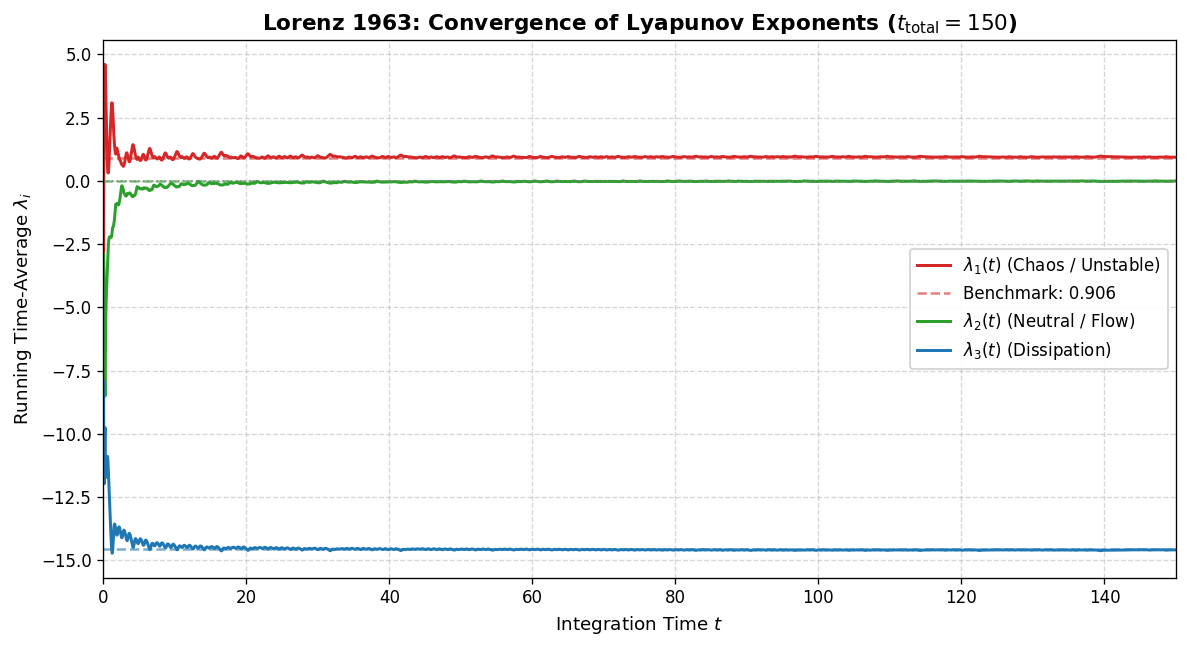

In [12]:
import time

t_total = 150.0
dt_qr = 0.05
params = (10.0, 28.0, 8.0 / 3.0)
y0 = [1.0, 1.0, 1.0]

print(f"Integrating Lorenz system for t = {t_total} with dt_qr = {dt_qr}...")
t_start = time.perf_counter()

t_vals, traj, lyap_times, lyap_history = solve_ivp_with_lyapunov(
    f=lorenz,
    df=lorenz_jacobian,
    y0=y0,
    t_total=t_total,
    dt_qr=dt_qr,
    args=params,
    method="RK45",
    lyap_mode="history",
    n_transient_steps=500,
)

print(f"Completed in {time.perf_counter() - t_start:.2f} seconds.\n")

# 4. Compare with Canonical Benchmarks
computed_final = np.sort(lyap_history[-1])[::-1]
benchmark = np.array([0.9056, 0.0000, -14.5723])
diff = np.abs(computed_final - benchmark)

print("=" * 60)
print(f"{'Exponent':<10} | {'Computed':<12} | {'Benchmark':<12} | {'Abs Error':<10}")
print("-" * 60)
for i in range(3):
    print(
        f"λ{i+1:<9} | {computed_final[i]:<12.4f} | {benchmark[i]:<12.4f} | {diff[i]:<10.4e}"
    )
print("=" * 60)
print(f"Trace Sum (div f) : {computed_final.sum():.4f} (Actual: -13.6667)")
print("=" * 60)

# 5. Plotting Historical Convergence
# Sort each row so curves represent λ1 >= λ2 >= λ3 across all times
sorted_history = np.sort(lyap_history, axis=1)[:, ::-1]

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=120)

colors = ["#d62728", "#2ca02c", "#1f77b4"]
labels = [
    r"$\lambda_1(t)$ (Chaos / Unstable)",
    r"$\lambda_2(t)$ (Neutral / Flow)",
    r"$\lambda_3(t)$ (Dissipation)",
]

for i in range(3):
    ax.plot(
        lyap_times,
        sorted_history[:, i],
        label=labels[i],
        color=colors[i],
        lw=1.8,
    )
    ax.axhline(
        benchmark[i],
        color=colors[i],
        linestyle="--",
        alpha=0.6,
        label=f"Benchmark: {benchmark[i]:.3f}" if i == 0 else "",
    )

ax.axhline(0, color="gray", linestyle=":", lw=1.0, alpha=0.8)
ax.set_title(
    "Lorenz 1963: Convergence of Lyapunov Exponents ($t_{\\mathrm{total}}=150$)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Integration Time $t$", fontsize=11)
ax.set_ylabel("Running Time-Average $\\lambda_i$", fontsize=11)
ax.set_xlim(0, t_total)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="right", framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

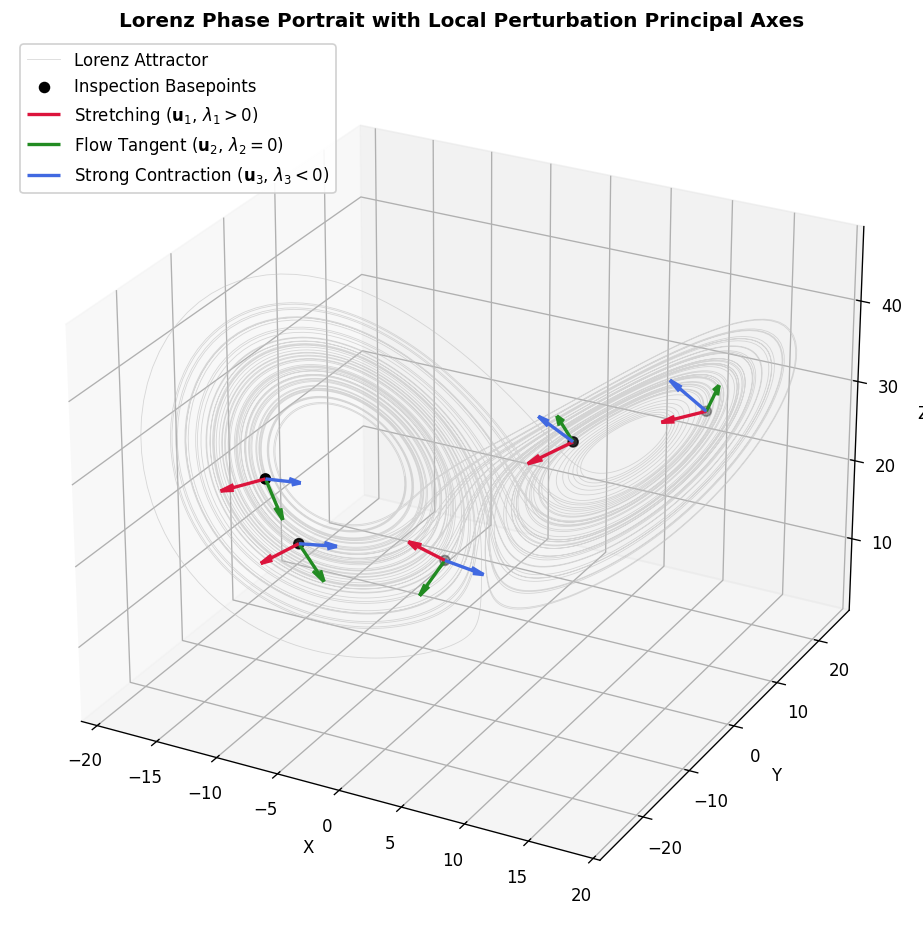

In [13]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np


# 1. Lorenz equations and Jacobian
def lorenz(y, sigma=10.0, rho=28.0, beta=8.0 / 3.0):
    x, y_c, z = y
    return np.array(
        [sigma * (y_c - x), x * (rho - z) - y_c, x * y_c - beta * z]
    )


def lorenz_jacobian(y, sigma=10.0, rho=28.0, beta=8.0 / 3.0):
    x, y_c, z = y
    return np.array([[-sigma, sigma, 0.0], [rho - z, -1.0, -x], [y_c, x, -beta]])


# 2. RK4 stepper integrating state and variational propagator simultaneously
def rk4_step_with_variational(y, Phi, h):
    # State stages
    k1 = lorenz(y)
    K1_phi = lorenz_jacobian(y) @ Phi

    k2 = lorenz(y + 0.5 * h * k1)
    K2_phi = lorenz_jacobian(y + 0.5 * h * k1) @ (Phi + 0.5 * h * K1_phi)

    k3 = lorenz(y + 0.5 * h * k2)
    K3_phi = lorenz_jacobian(y + 0.5 * h * k2) @ (Phi + 0.5 * h * K2_phi)

    k4 = lorenz(y + h * k3)
    K4_phi = lorenz_jacobian(y + h * k3) @ (Phi + h * K3_phi)

    y_next = y + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    Phi_next = Phi + (h / 6.0) * (K1_phi + 2 * K2_phi + 2 * K3_phi + K4_phi)
    return y_next, Phi_next


# 3. Generate background attractor
h = 0.005
n_steps = 15000
y = np.array([1.0, 1.0, 1.0])

# Burn-in transient
for _ in range(2000):
    k1 = lorenz(y)
    k2 = lorenz(y + 0.5 * h * k1)
    k3 = lorenz(y + 0.5 * h * k2)
    k4 = lorenz(y + h * k3)
    y += (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

# Record trajectory
traj = np.zeros((n_steps, 3))
for i in range(n_steps):
    k1 = lorenz(y)
    k2 = lorenz(y + 0.5 * h * k1)
    k3 = lorenz(y + 0.5 * h * k2)
    k4 = lorenz(y + h * k3)
    y += (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    traj[i] = y

# 4. Compute local perturbation deformation at selected sample points
sample_indices = [
    2500,
    4200,
    7000,
    9500,
    12000,
]  # Pick distinctive points on both wings
tau_steps = 40  # Look-ahead window (delta_t = 40 * 0.005 = 0.2)

arrow_origins = []
stretch_dirs = []  # u1
flow_dirs = []  # u2
shrink_dirs = []  # u3

for idx in sample_indices:
    y_pt = traj[idx].copy()
    Phi = np.eye(3)

    # Integrate forward for a short interval tau to capture the local flow distortion
    for _ in range(tau_steps):
        y_pt, Phi = rk4_step_with_variational(y_pt, Phi, h)

    # SVD of the finite-time propagator: Phi = U @ S @ Vt
    U, S, Vt = np.linalg.svd(Phi)

    arrow_origins.append(traj[idx])
    stretch_dirs.append(U[:, 0])  # Dominant stretching direction
    flow_dirs.append(U[:, 1])  # Flow / neutral direction
    shrink_dirs.append(U[:, 2])  # Strongest contraction direction

arrow_origins = np.array(arrow_origins)
stretch_dirs = np.array(stretch_dirs)
flow_dirs = np.array(flow_dirs)
shrink_dirs = np.array(shrink_dirs)

# 5. Plot 3D Phase Portrait with Perturbation Directions
fig = plt.figure(figsize=(11, 8), dpi=120)
ax = fig.add_subplot(111, projection="3d")

# Draw attractor trajectory
ax.plot(
    traj[:, 0],
    traj[:, 1],
    traj[:, 2],
    color="silver",
    lw=0.5,
    alpha=0.6,
    label="Lorenz Attractor",
)

# Plot inspection points
ax.scatter(
    arrow_origins[:, 0],
    arrow_origins[:, 1],
    arrow_origins[:, 2],
    color="black",
    s=35,
    zorder=5,
    label="Inspection Basepoints",
)

scale = 4.5  # Length multiplier for visualization

# Red arrows: Stretching direction (lambda_1 > 0)
ax.quiver(
    arrow_origins[:, 0],
    arrow_origins[:, 1],
    arrow_origins[:, 2],
    stretch_dirs[:, 0] * scale,
    stretch_dirs[:, 1] * scale,
    stretch_dirs[:, 2] * scale,
    color="crimson",
    lw=2.0,
    label=r"Stretching ($\mathbf{u}_1$, $\lambda_1 > 0$)",
)

# Green arrows: Flow / Neutral direction (lambda_2 = 0)
ax.quiver(
    arrow_origins[:, 0],
    arrow_origins[:, 1],
    arrow_origins[:, 2],
    flow_dirs[:, 0] * scale,
    flow_dirs[:, 1] * scale,
    flow_dirs[:, 2] * scale,
    color="forestgreen",
    lw=2.0,
    label=r"Flow Tangent ($\mathbf{u}_2$, $\lambda_2 = 0$)",
)

# Blue arrows: Shrinking / Crushing direction (lambda_3 < 0)
ax.quiver(
    arrow_origins[:, 0],
    arrow_origins[:, 1],
    arrow_origins[:, 2],
    shrink_dirs[:, 0] * scale,
    shrink_dirs[:, 1] * scale,
    shrink_dirs[:, 2] * scale,
    color="royalblue",
    lw=2.0,
    label=r"Strong Contraction ($\mathbf{u}_3$, $\lambda_3 < 0$)",
)

ax.set_title(
    "Lorenz Phase Portrait with Local Perturbation Principal Axes",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.legend(loc="upper left", framealpha=0.9)
ax.view_init(elev=26, azim=-62)

plt.tight_layout()
plt.show()